# Assurance voyage – nettoyage, EDA, segmentation et prédiction des sinistres

**Objectif** : comprendre quels profils de polices génèrent des sinistres, segmenter la clientèle (K-Means / CAH) puis tester si un modèle de machine learning sait repérer les polices à risque malgré un déséquilibre de classes extrême (~1 % de sinistres).

Le code réutilisable est dans le package `travel_insurance/` ; ce notebook raconte la démarche et commente les résultats.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from travel_insurance import config as cfg, data, eda, clustering, modeling
%matplotlib inline
pd.set_option('display.width', 140)

## 1. Chargement et aperçu

In [2]:
raw = data.load_raw()
print(raw.shape)
display(raw.head())
display(raw.describe(include='all').T)

(21300, 11)


,Agency,Agency_Type,Distribution_Channel,Product_Name,Claim_Status,Duration,Destination,Net_Sales,Commission,Gender,Age
0,JZI,Airlines,Online,Basic Plan,No,104.0,"TAIWAN, PROVINCE OF CHINA",35.0,12.25,M,34.0
1,EPX,Travel Agency,Online,Cancellation Plan,No,47.0,CHILE,80.0,0.00,NaN,36.0
2,EPX,Travel Agency,Online,2 way Comprehensive Plan,No,63.0,CHINA,35.0,0.00,NaN,36.0
3,EPX,Travel Agency,Online,2 way Comprehensive Plan,No,39.0,INDONESIA,20.0,0.00,NaN,36.0
4,EPX,Travel Agency,Online,Cancellation Plan,No,21.0,INDIA,29.0,0.00,NaN,36.0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Agency,21300,13,EPX,13553,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Agency_Type,21300,2,Travel Agency,16805,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Distribution_Channel,21300,2,Online,21136,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Name,21300,15,Cancellation Plan,7282,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Claim_Status,21299,2,No,21105,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Duration,21299.0,NaN,NaN,NaN,47.177238,112.548079,-2.0,10.0,23.0,53.0,4881.0
Destination,21299,122,SINGAPORE,2917,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Net_Sales,21299.0,NaN,NaN,NaN,37.586096,43.274026,-389.0,18.0,26.0,44.0,810.0
Commission,21299.0,NaN,NaN,NaN,7.981518,16.760875,0.0,0.0,0.0,9.1,283.5
Gender,4338,2,M,2397,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Points d'attention visibles dès l'aperçu** : `Gender` est renseigné pour ~20 % des lignes seulement, `Duration` contient des valeurs ≤ 0, `Age` contient des valeurs impossibles (118), et la dernière ligne du fichier est vide.

## 2. Nettoyage

In [3]:
df, log = data.clean(raw)
pd.Series(log)

n_raw                 21300.0
n_empty_rows              1.0
n_duplicates           1896.0
n_invalid_duration       20.0
n_invalid_age           255.0
gender_missing_pct       78.6
n_clean               19383.0
age_missing_after       255.0
dtype: float64

In [4]:
# Où sont les valeurs « bouchon » ?
print("Age = 36 :", f"{(raw.Age == 36).mean():.1%} des lignes (valeur par défaut probable)")
print(raw.loc[raw.Age > 100, 'Agency'].value_counts().head(3).to_dict(), "← Age > 100 concentré sur une agence")
print("Gender manquant par type d'agence :")
display(raw.groupby('Agency_Type')['Gender'].apply(lambda s: s.isna().mean()).round(3))

Age = 36 : 46.0% des lignes (valeur par défaut probable)
{'JWT': 257, 'JZI': 25, 'CCR': 23} ← Age > 100 concentré sur une agence
Gender manquant par type d'agence :


Agency_Type
Airlines         0.098
Travel Agency    0.983
Name: Gender, dtype: float64

**Décisions de nettoyage (et pourquoi)**

| Problème | Traitement | Justification |
|---|---|---|
| 1 ligne vide | supprimée | aucune information |
| 1 896 doublons exacts | supprimés | évite de compter deux fois la même police (et une fuite train/test) — *hypothèse* : un doublon est une erreur d'import |
| Duration ≤ 0 | supprimées | durée de voyage impossible |
| Age > 100 | → `NaN` | 118 est une valeur bouchon, pas un âge |
| Gender manquant (78,6 %) | catégorie `Unknown` | l'imputer par le mode (« M ») inventerait 15 000 valeurs ; de plus l'absence de genre est un artefact de collecte par agence (voir §3) |
| Valeurs extrêmes | **conservées** | winsorisation appliquée seulement dans le clustering, pas sur les données sauvegardées |

## 3. Analyse exploratoire

In [5]:
res_eda = eda.run_eda(df, save=False)
res_eda['target']

{'n': 19383, 'claims': 194, 'rate_pct': 1.0}

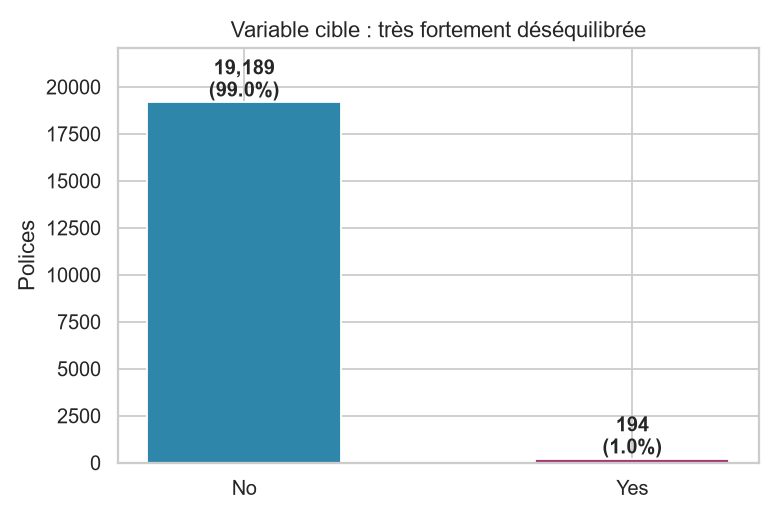

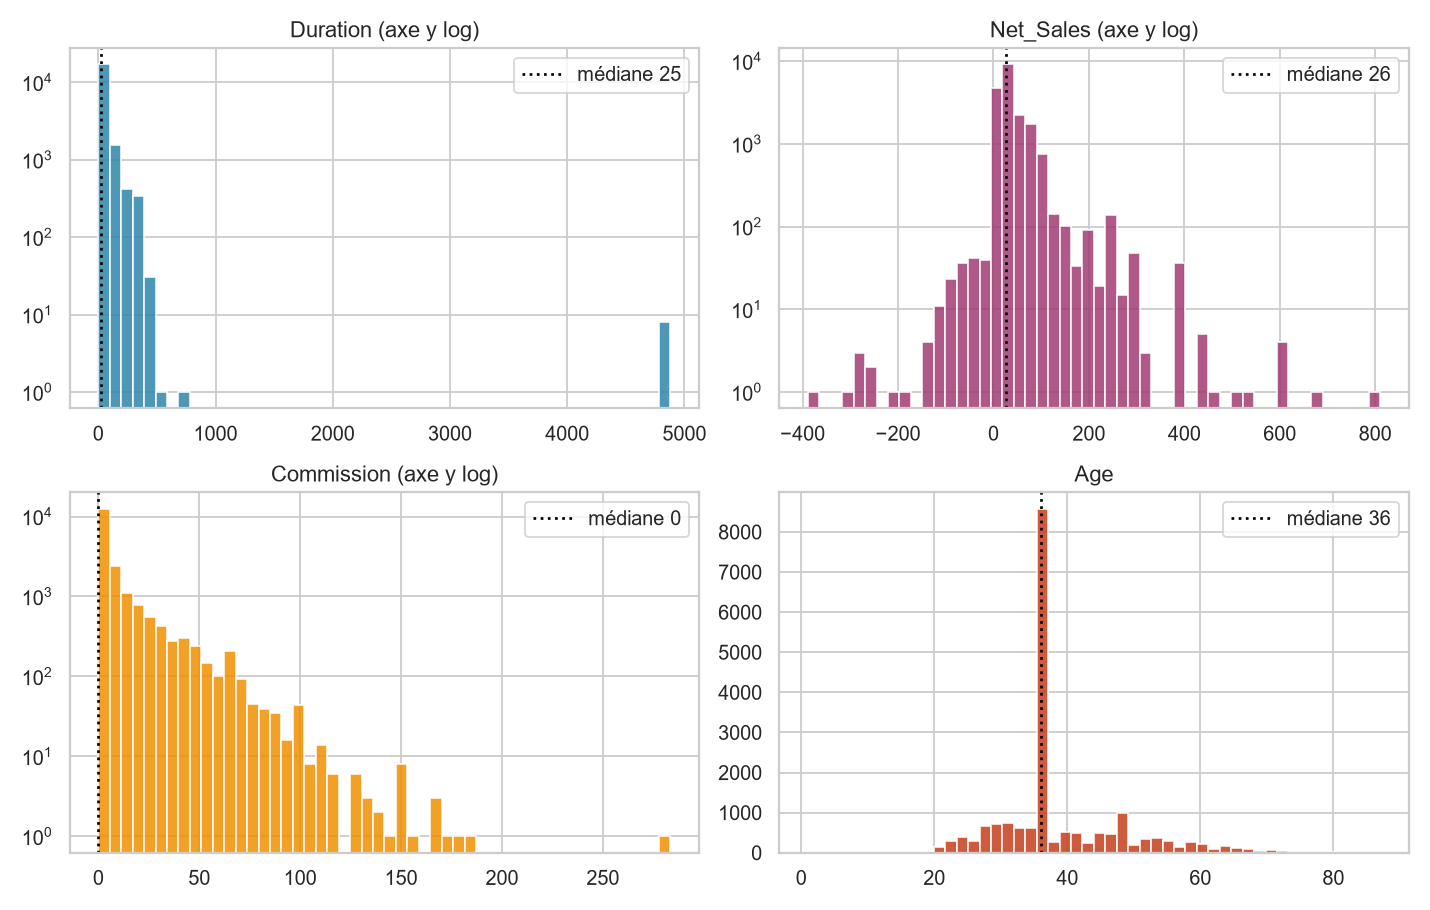

In [6]:
fig_names = ['01_target', '02_distributions']
for n in fig_names: display(Image(filename=f'../reports/figures/{n}.png'))

La cible est **très déséquilibrée** : 194 sinistres pour 19 383 polices (1,0 %). L'*accuracy* est donc inutilisable (un modèle qui répond toujours « pas de sinistre » a 99 %). On utilisera la PR-AUC et le rappel dans le top-décile.

### Quelles variables sont liées au sinistre ? (tests statistiques)

In [7]:
chi = pd.DataFrame(res_eda['chi2']).T[['chi2', 'dof', 'p_value']]
display(chi.style.format({'p_value': '{:.2e}'}))
display(pd.DataFrame(res_eda['mannwhitney']).T.style.format({'p_value': '{:.2e}'}))

,chi2,dof,p_value
Agency_Type,104.090000,1.000000,1.94e-24
Distribution_Channel,0.000000,1.000000,1.00e+00
Agency,511.980000,12.000000,6.23e-102
Product_Name,1003.200000,14.000000,3.22e-205
Gender_known,107.690000,1.000000,3.14e-25


,median_claim,median_no_claim,p_value
Duration,55.500000,25.000000,2.46e-19
Net_Sales,69.300000,26.000000,1.14e-38
Commission,15.375000,0.000000,1.23e-28
Age,36.000000,36.000000,1.48e-01


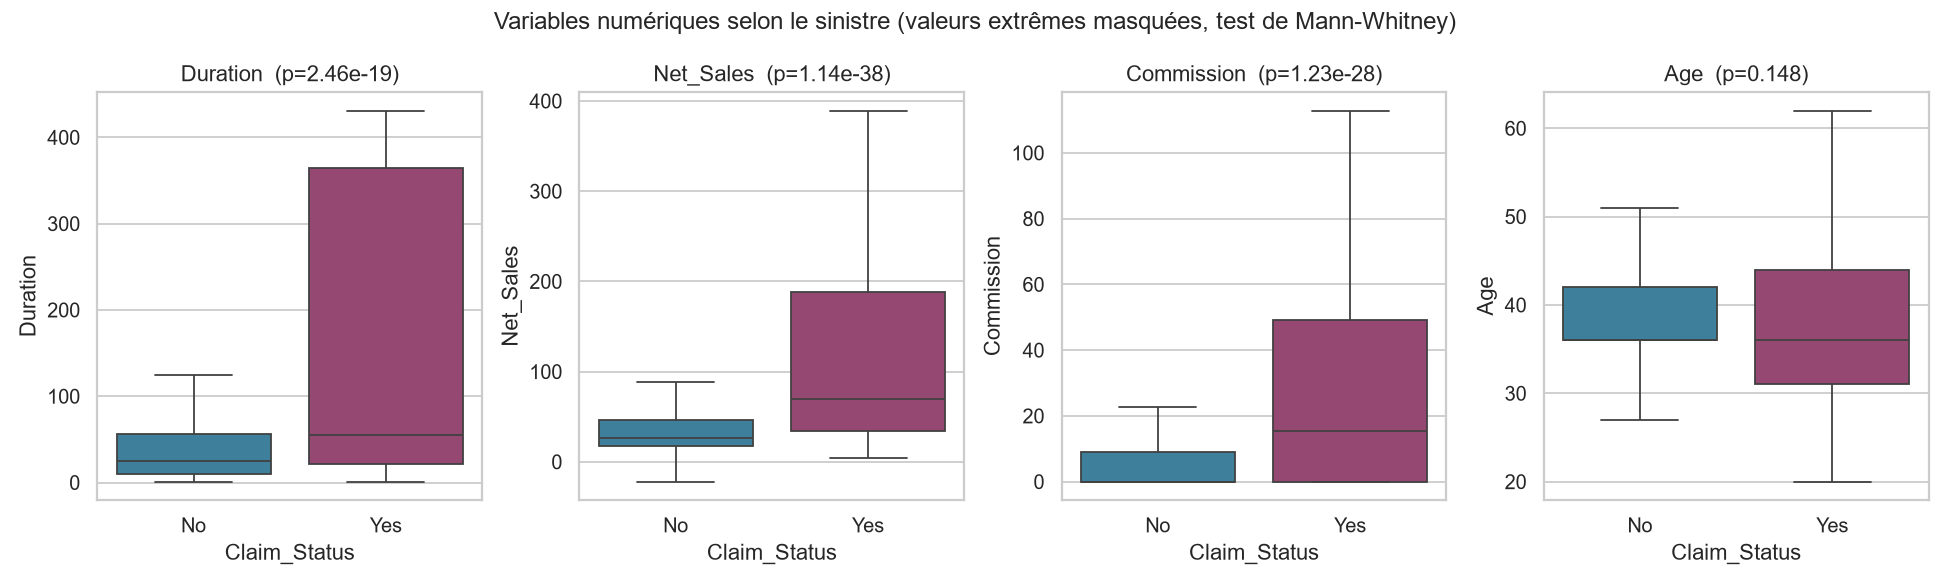

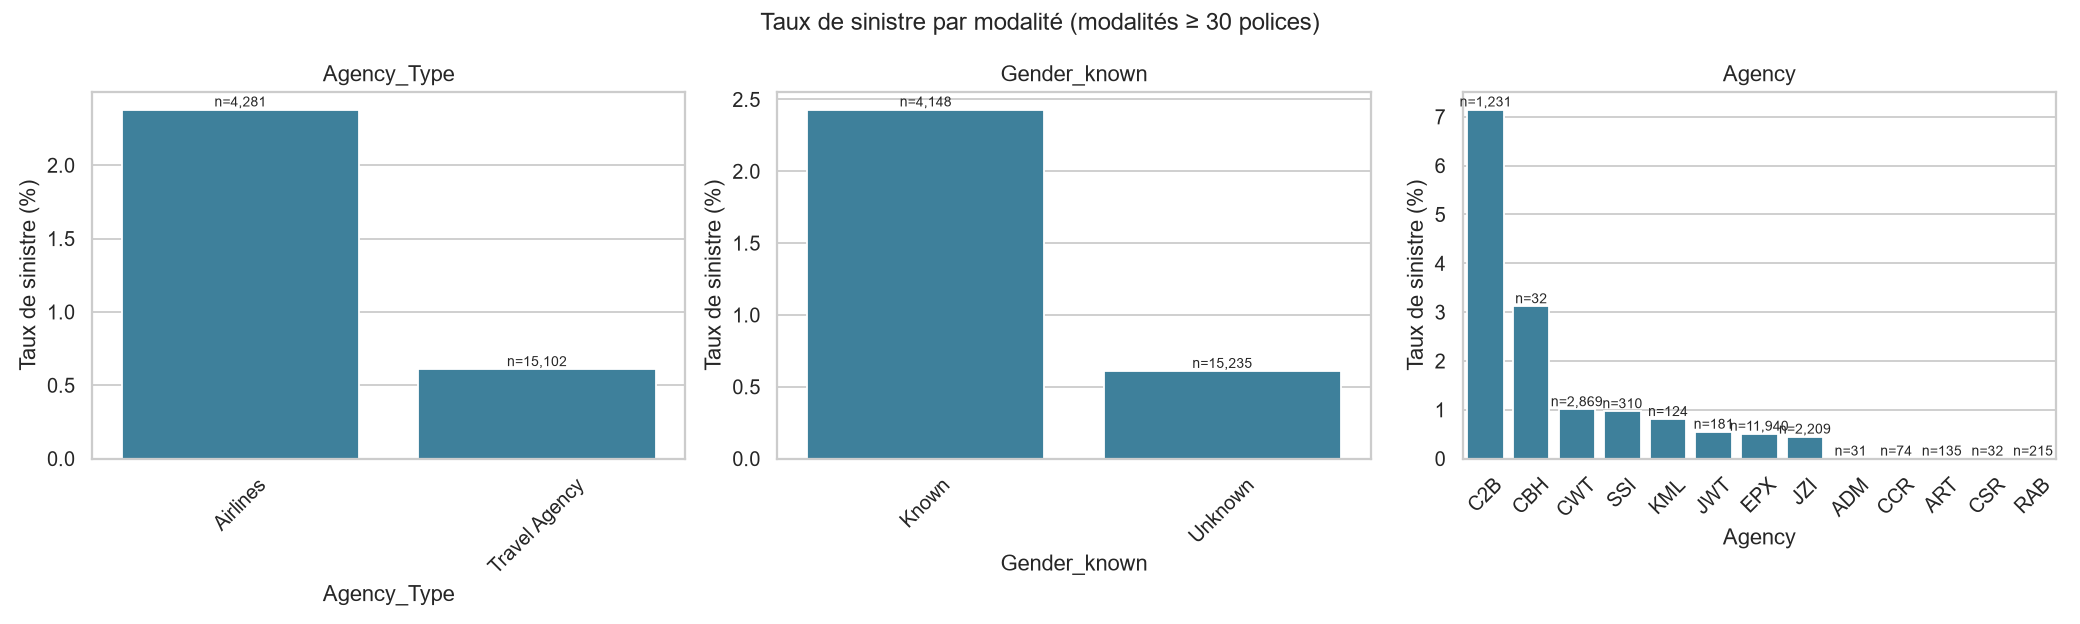

In [8]:
for n in ['03_numeric_vs_claim', '04_claim_rate_by_category']:
    display(Image(filename=f'../reports/figures/{n}.png'))

**Lecture**
- `Duration`, `Net_Sales` et `Commission` sont significativement plus élevées chez les polices avec sinistre (Mann-Whitney, p < 1e-18) ; **l'âge n'est pas discriminant** (p ≈ 0,15).
- Le **type d'agence** est lié au sinistre (Airlines 2,4 % vs Travel Agency 0,6 %), tout comme l'**agence** (C2B : 7 %) et le **produit** (Annual Silver Plan : ~19 %).
- Le **canal de distribution n'apporte rien** (p = 1,0 ; 99,2 % des polices sont « Online » → quasi-constante).
- **Genre renseigné vs inconnu** : 2,4 % contre 0,6 % de sinistres. Mais le genre est **absent à 100 % pour les agences EPX, CWT et SSI** (et présent à ~100 % pour la plupart des autres) : « genre inconnu » n'est donc pas un comportement client, c'est un **proxy de l'agence**. L'imputer par le mode aurait masqué cela et fabriqué 15 000 valeurs.
- ⚠️ Corrélation ≠ causalité : les produits « Annual » ont de longues durées, et les agences vendent des produits différents.

> Le texte d'une version antérieure du projet affirmait `Net_Sales`/`Commission` corrélés à r ≈ 0,7. Mesuré ici (Spearman) : **0,24**. Les interprétations sont maintenant calculées, plus écrites à la main.

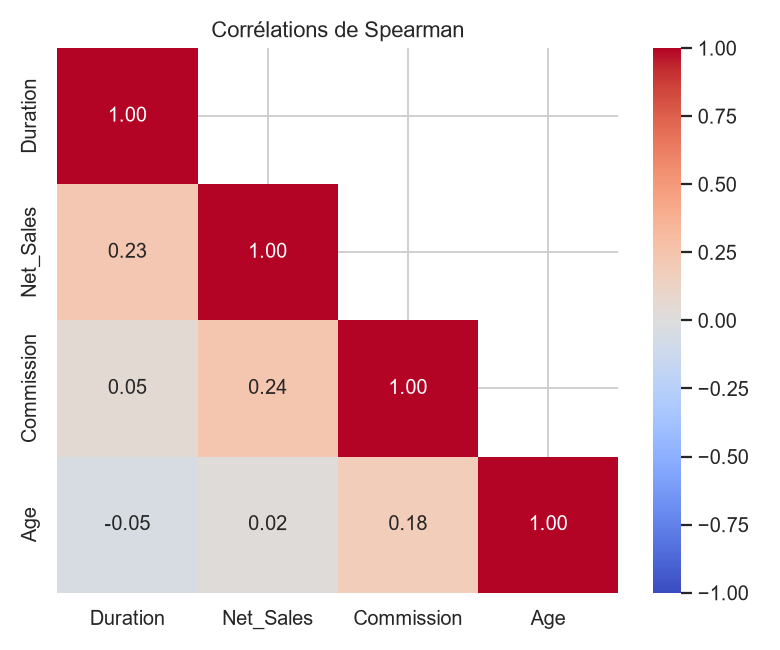

In [9]:
display(Image(filename='../reports/figures/06_correlation.png'))

> **Limite des données** : 42,6 % des âges valent exactement 36 → valeur par défaut du système de saisie. L'absence de lien entre âge et sinistre est donc à prendre avec prudence.

## 4. Segmentation (clustering)

In [10]:
df_cl, res_cl = clustering.run_clustering(df, save=False)
print({k: v for k, v in res_cl.items() if k != 'profiles'})
display(pd.DataFrame(res_cl['profiles']).set_index('Cluster'))

{'k_candidates': {'k': [2, 3, 4, 5, 6, 7, 8], 'silhouette': [0.58, 0.426, 0.451, 0.455, 0.446, 0.44, 0.398]}, 'k_best_silhouette': 2, 'k_used': 4, 'silhouette_kmeans': 0.451, 'silhouette_cah': 0.442, 'ari_kmeans_vs_cah': 0.919}


,n,duration_med,net_sales_med,commission_med,age_med,airline_pct,claims,claim_rate_pct
Cluster,,,,,,,,
0,13445,25.0,24.00,0.00,36.0,0.00,74,0.55
1,3858,17.0,25.32,7.70,43.0,100.00,44,1.14
2,1745,38.0,69.30,41.58,43.0,6.02,22,1.26
3,335,367.0,252.85,63.21,40.0,94.93,54,16.12


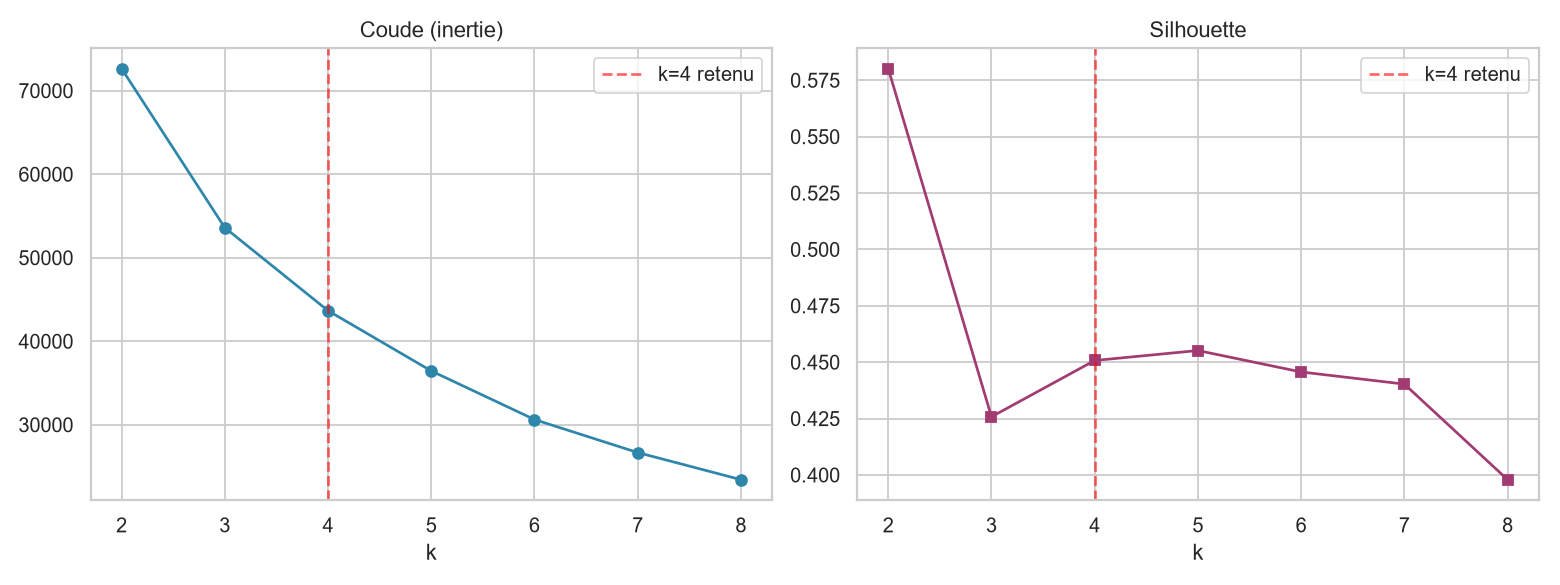

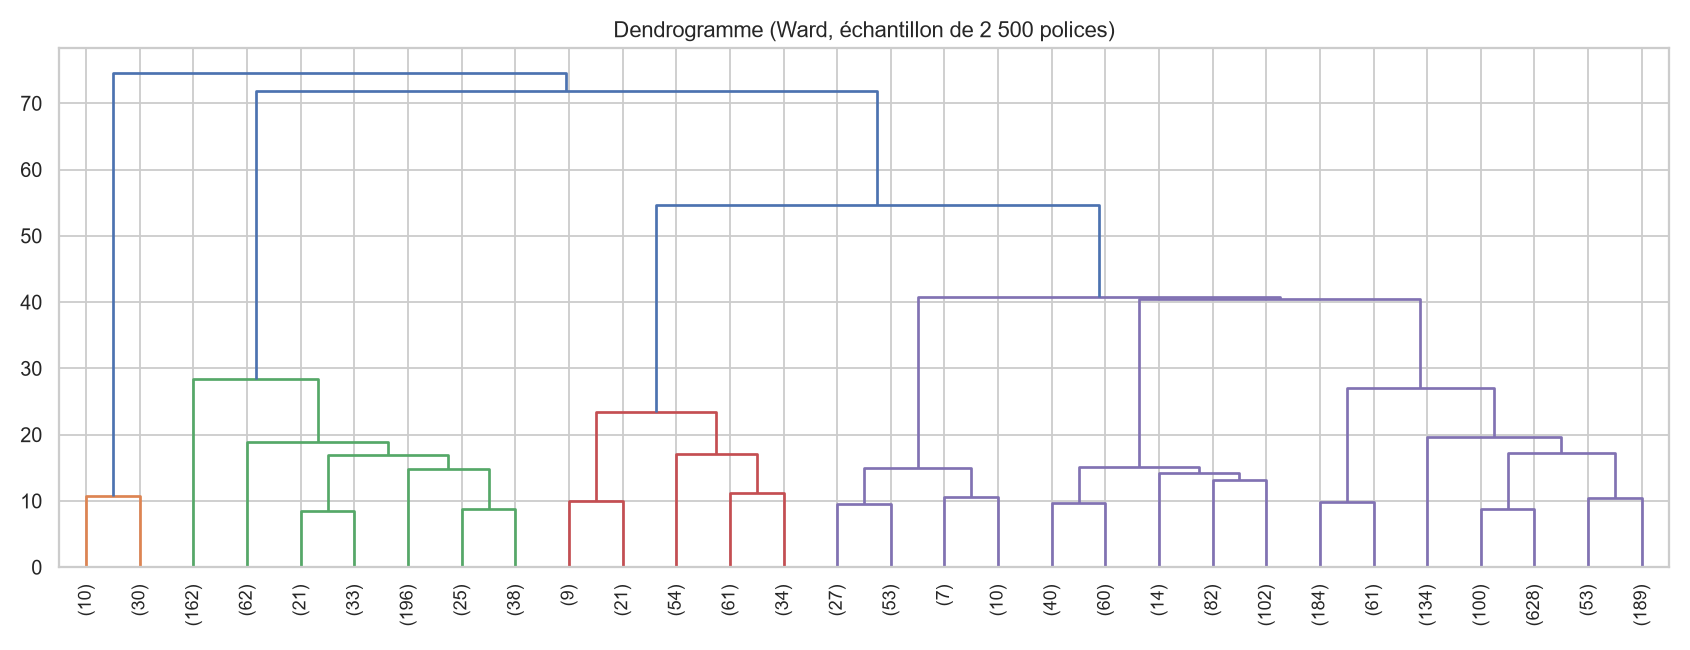

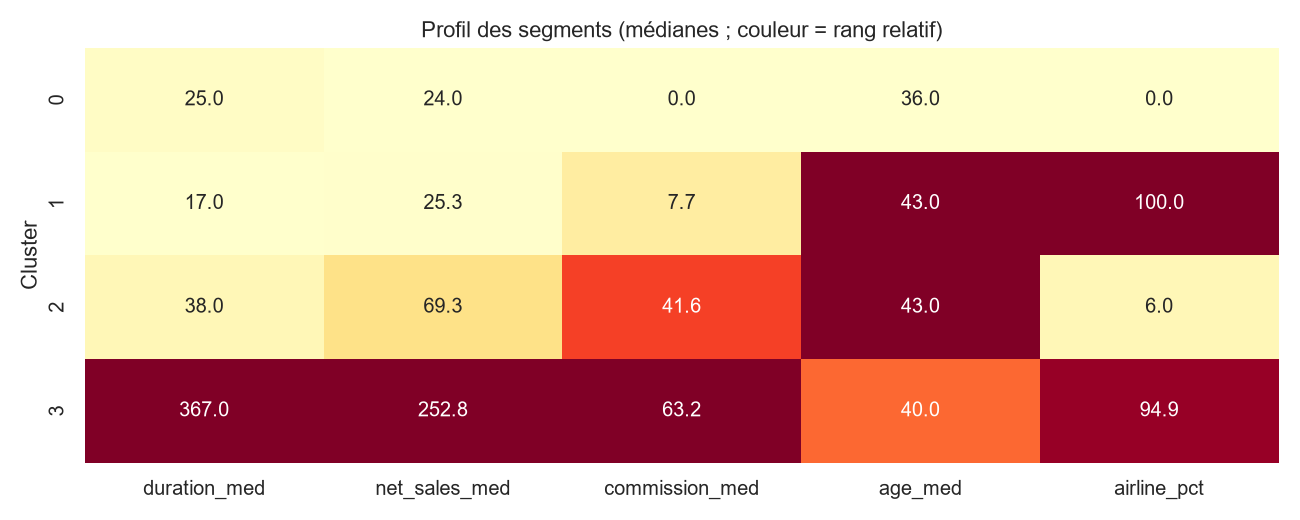

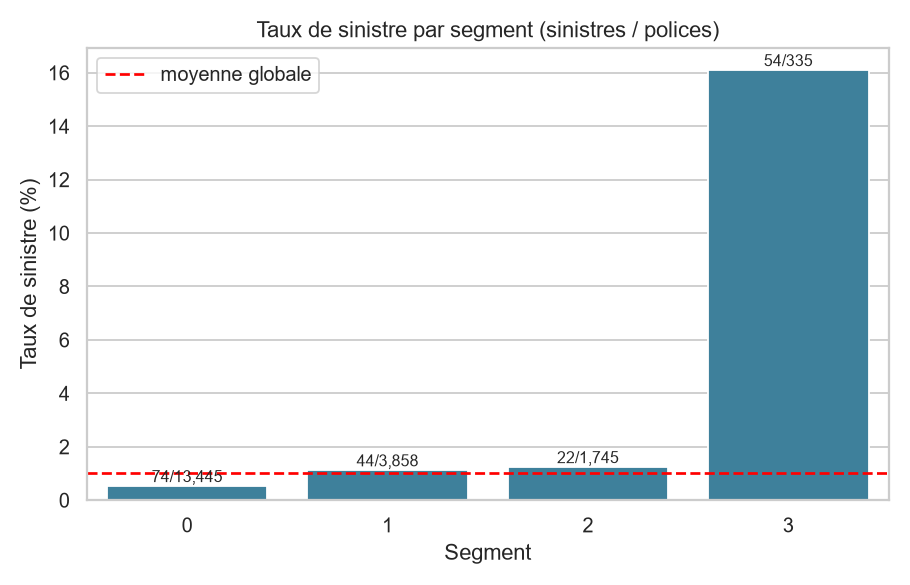

In [11]:
for n in ['07_elbow_silhouette', '08_dendrogram', '09_cluster_profiles', '10_claim_rate_by_cluster']:
    display(Image(filename=f'../reports/figures/{n}.png'))

**Choix de k.** La silhouette est maximale pour k = 2 (0,58 : simple séparation « long séjour » / « court »), puis plateau autour de 0,45 pour k = 3 à 7. On retient **k = 4** (silhouette 0,45) : le coude est peu marqué, et k = 4 est le plus petit k qui isole un segment à très haut risque exploitable commercialement. C'est un **choix métier assumé**, pas une optimisation.

**Les 4 segments (numérotés par Net_Sales médian croissant)**

| Segment | Profil | Sinistres |
|---|---|---|
| 0 | agences de voyage, séjours courts, sans commission (69 % des polices) | 0,55 % |
| 1 | compagnies aériennes, séjours courts | 1,14 % |
| 2 | primes/commissions élevées via agences, durée moyenne | 1,26 % |
| 3 | **séjours très longs (~1 an), primes élevées**, surtout via compagnies aériennes (335 polices) | **16,1 %** |

Le segment 3 ne représente que 1,7 % des polices mais **28 % des sinistres** (54/194). K-Means et CAH (Ward) sont très proches (ARI = 0,92), ce qui indique une structure stable.

## 5. Modélisation prédictive du sinistre

In [12]:
res_ml = modeling.run_modeling(df, save=False)
display(pd.DataFrame({k: {m: v[m] for m in ('roc_auc', 'pr_auc')} for k, v in res_ml['cv'].items()}).T)
print("Taux de base (PR-AUC d'un modèle au hasard) :", res_ml['baseline_pr_auc'])
print("Meilleur modèle :", res_ml['best_model'])
res_ml['holdout']

,roc_auc,pr_auc
Baseline (prior),0.500 ± 0.000,0.010 ± 0.000
Régression logistique,0.810 ± 0.055,0.105 ± 0.058
Random Forest,0.817 ± 0.062,0.094 ± 0.046
Gradient Boosting,0.816 ± 0.055,0.101 ± 0.051


Taux de base (PR-AUC d'un modèle au hasard) : 0.01
Meilleur modèle : Régression logistique


{'n_test': 4846,
 'claims_test': 49,
 'roc_auc': 0.794,
 'pr_auc': 0.105,
 'recall_in_top10pct': 0.531,
 'recall_in_top20pct': 0.694}

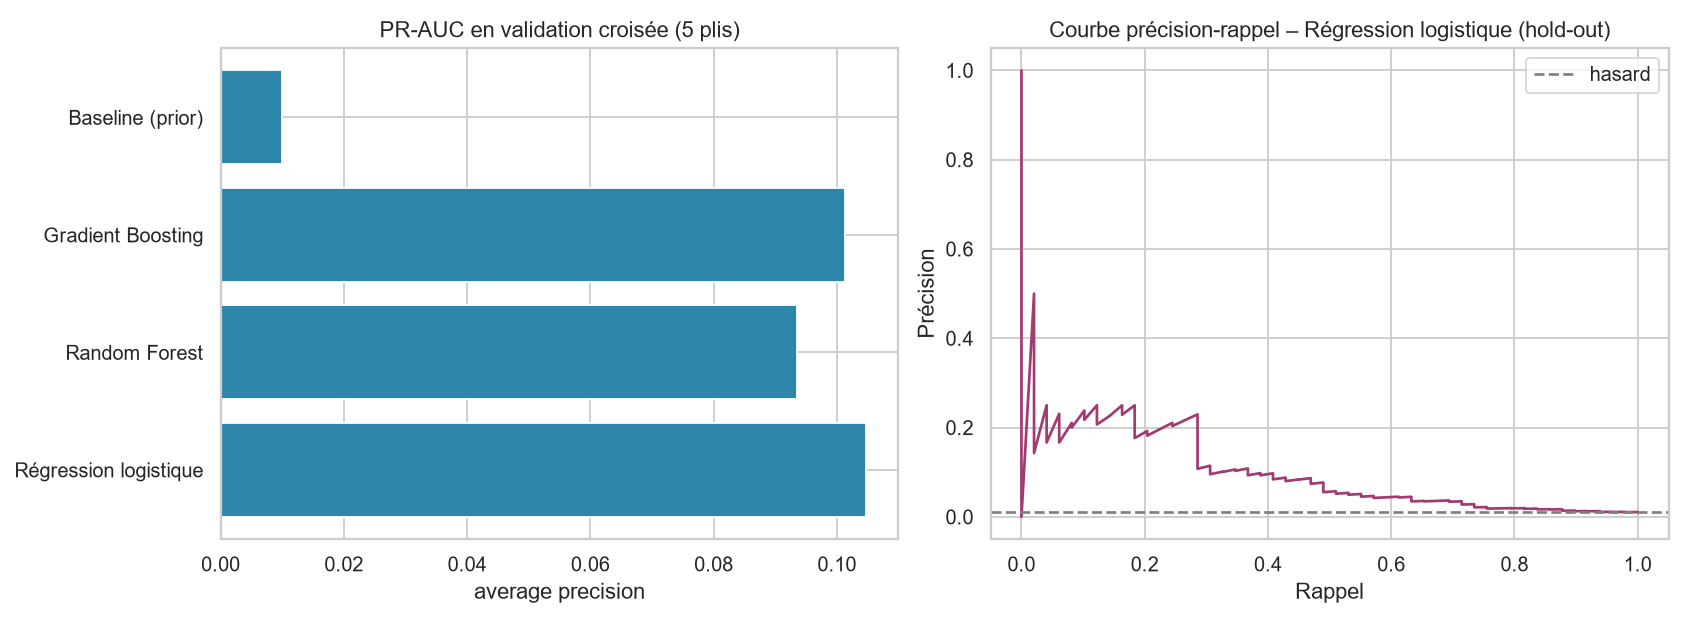

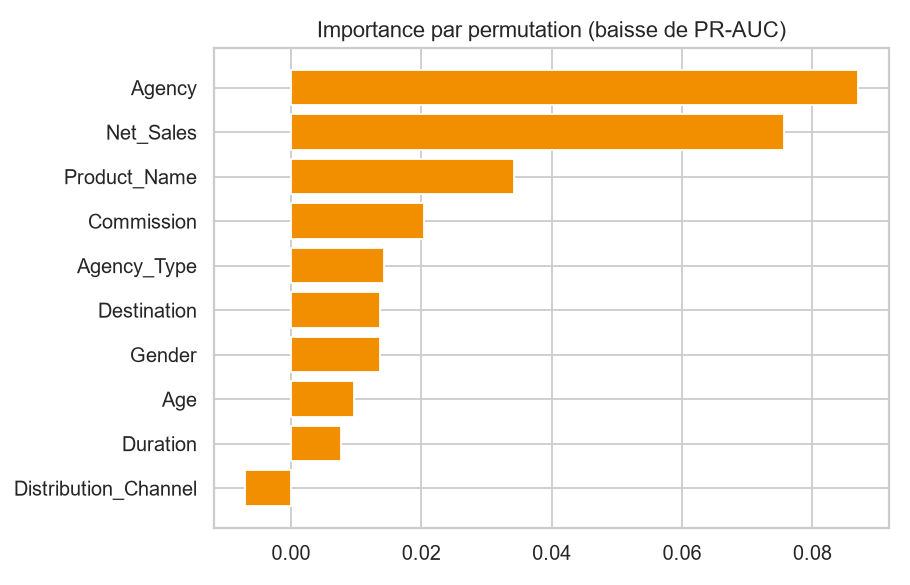

In [13]:
for n in ['11_model_comparison', '12_feature_importance']:
    display(Image(filename=f'../reports/figures/{n}.png'))

**Méthodologie** : pipeline complet (imputation, log-transformation, encodage) réappris dans chaque pli → pas de fuite ; validation croisée stratifiée 5 plis ; doublons supprimés en amont ; déséquilibre traité par pondération des classes.

**Résultats** (honnêtes) :
- ROC-AUC ≈ 0,81 et PR-AUC ≈ 0,10, soit **10× le hasard** (0,01), mais une précision absolue faible : le modèle **classe** bien le risque, il ne **prédit pas** un sinistre individuel de façon fiable.
- Sur le hold-out, les 10 % de polices les mieux classées contiennent **~53 % des sinistres** (69 % pour le top 20 %) – utile pour prioriser un contrôle ou une tarification.
- Les trois modèles sont statistiquement indistinguables (écart-type entre plis ≈ 0,05, avec seulement 194 sinistres) → on privilégie la **régression logistique**, la plus simple et interprétable.
- Variables les plus importantes : `Agency`, `Net_Sales`, `Product_Name`.

**Limites** : 194 positifs seulement, variance élevée ; pas de dimension temporelle (impossible de vérifier un décalage dans le temps) ; l'agence et le produit étant fortement liés, l'importance n'est pas une causalité.

## 6. Conclusion

1. **Qualité des données** : doublons, valeurs bouchon (âge 36/118), genre absent à 79 % → problème de collecte à la source, à corriger avant toute exploitation.
2. **Risque** : très concentré – séjours longs/annuels, certains produits (*Annual Silver Plan*) et certaines agences (C2B). Le genre inconnu n'est qu'un proxy de l'agence (EPX, CWT et SSI ne le collectent jamais).
3. **Segmentation** : un petit segment (1,7 % des polices) porte 28 % des sinistres.
4. **Prédiction** : un modèle simple apporte un gain réel (×10 en PR-AUC) pour prioriser, mais pas assez pour automatiser une décision.
5. **Pistes** : plus de données (positives), variables temporelles et de montants de sinistre, calibration des probabilités, analyse coût/bénéfice du seuil de décision.